<a href="https://colab.research.google.com/github/Subhana729/PROJECT/blob/main/lab02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original shapes:
X_raw: (400, 2)
y_raw: (400,)

Required shapes:
X: (2, 400)
Y: (1, 400)


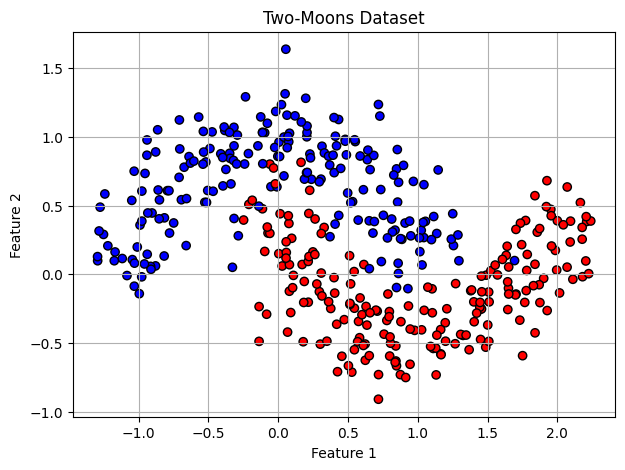


Train/Test shapes:
X_train: (2, 320)
Y_train: (1, 320)
X_test : (2, 80)
Y_test : (1, 80)

Sigmoid verification:
sigmoid(0)     = 0.5
sigmoid(-1000) = 0.0
sigmoid(1000)  = 1.0

Sigmoid plot arrays:
z shape: (400,)
a shape: (400,)


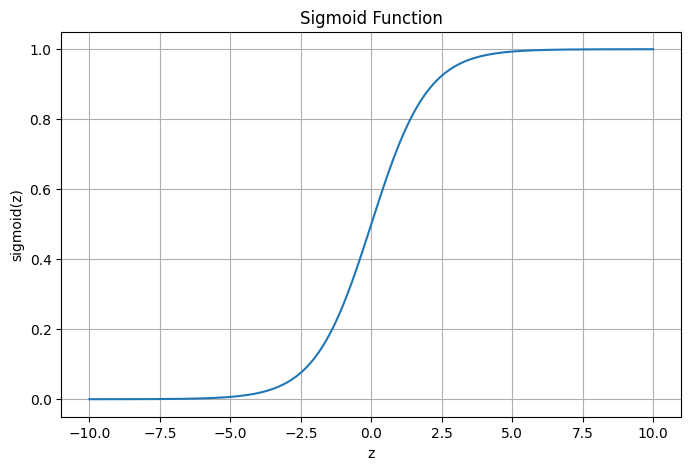

In [ ]:
# ============================================================
# LAB 02 - TASK 1
# Data Preparation and the Sigmoid Function
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons


# ============================================================
# STEP 1: Create the two-moons dataset
# ============================================================

X_raw, y_raw = make_moons(
    n_samples=400,
    noise=0.20,
    random_state=1
)

print("Original shapes:")
print("X_raw:", X_raw.shape)
print("y_raw:", y_raw.shape)


# ============================================================
# STEP 2: Convert to (n, m) convention
# ============================================================

X = X_raw.T
Y = y_raw.reshape(1, -1)

print("\nRequired shapes:")
print("X:", X.shape)
print("Y:", Y.shape)


# ============================================================
# STEP 3: Plot complete dataset
# ============================================================

plt.figure(figsize=(7, 5))

plt.scatter(
    X[0],
    X[1],
    c=Y.ravel(),
    cmap='bwr',
    edgecolors='k'
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-Moons Dataset")
plt.grid(True)
plt.show()


# ============================================================
# STEP 4: Split into training and testing data
# ============================================================

m_train = 320

X_train = X[:, :m_train]
Y_train = Y[:, :m_train]

X_test = X[:, m_train:]
Y_test = Y[:, m_train:]

print("\nTrain/Test shapes:")
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test :", X_test.shape)
print("Y_test :", Y_test.shape)


# ============================================================
# STEP 5: Implement sigmoid
# ============================================================

def sigmoid(z):

    z = np.asarray(z)

    result = np.empty_like(z, dtype=float)

    positive = z >= 0
    negative = z < 0

    # Positive values
    result[positive] = 1 / (
        1 + np.exp(-z[positive])
    )

    # Negative values
    exp_z = np.exp(z[negative])

    result[negative] = (
        exp_z / (1 + exp_z)
    )

    return result


# ============================================================
# STEP 6: Verify sigmoid
# ============================================================

print("\nSigmoid verification:")

print("sigmoid(0)     =", sigmoid(0))
print("sigmoid(-1000) =", sigmoid(-1000))
print("sigmoid(1000)  =", sigmoid(1000))


# ============================================================
# STEP 7: Plot sigmoid from -10 to 10
# ============================================================

z = np.linspace(-10, 10, 400)

a = sigmoid(z)

print("\nSigmoid plot arrays:")
print("z shape:", z.shape)
print("a shape:", a.shape)


plt.figure(figsize=(8, 5))

plt.plot(z, a)

plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Sigmoid Function")
plt.grid(True)

plt.show()

In [ ]:
# ==========================================
# TASK 2 - COMPLETE SOLUTION
# Forward Propagation and Cost
# ==========================================

def initialize(n):
    w = np.zeros((n, 1))
    b = 0.0
    return w, b


def forward(w, b, X):
    Z = w.T @ X + b
    A = sigmoid(Z)

    # A must have shape (1, m)
    assert A.shape == (1, X.shape[1])

    return A


def compute_cost(A, Y):
    m = Y.shape[1]
    eps = 1e-8

    cost = -(1/m) * np.sum(
        Y * np.log(A + eps) +
        (1 - Y) * np.log(1 - A + eps)
    )

    cost = float(np.squeeze(cost))

    # Cost must be a scalar
    assert np.isscalar(cost)

    return cost


# Initialize parameters
n = X_train.shape[0]
w, b = initialize(n)

# Forward propagation
A = forward(w, b, X_train)

# Cost
cost = compute_cost(A, Y_train)


# Display results
print("========== TASK 2 RESULTS ==========")
print("Number of features:", n)
print("w shape:", w.shape)
print("b:", b)
print("A shape:", A.shape)
print("Initial cost:", cost)

print("\nExpected initial cost: approximately 0.6931")
print("sigmoid(0):", sigmoid(0))

========== TASK 2 RESULTS ==========
Number of features: 2
w shape: (2, 1)
b: 0.0
A shape: (1, 320)
Initial cost: 0.6931471605599455

Expected initial cost: approximately 0.6931
sigmoid(0): 0.5


In [ ]:
# ============================================================
# TASK 3 - BACKWARD PROPAGATION AND GRADIENT CHECKING
# ============================================================

# ------------------------------------------------------------
# 1. Backward propagation
# ------------------------------------------------------------

def backward(X, A, Y):
    m = X.shape[1]

    # Derivative of cost with respect to Z
    dZ = A - Y

    # Gradient of weights
    dw = (1/m) * (X @ dZ.T)

    # Gradient of bias
    db = (1/m) * np.sum(dZ)

    return dw, db


# ------------------------------------------------------------
# 2. Calculate analytical gradients
# ------------------------------------------------------------

dw, db = backward(X_train, A, Y_train)

print("========== SHAPE CHECK ==========")
print("w shape :", w.shape)
print("dw shape:", dw.shape)
print("db      :", db)

assert dw.shape == w.shape
assert A.shape == Y_train.shape
assert np.isscalar(db)

print("✅ Shape checks passed!")


# ------------------------------------------------------------
# 3. Numerical gradient for weights
# ------------------------------------------------------------

def numerical_gradient_w(w, b, X, Y, epsilon=1e-7):

    grad = np.zeros_like(w, dtype=float)

    for i in range(w.shape[0]):

        # theta + epsilon
        w_plus = w.copy()
        w_plus[i, 0] += epsilon

        A_plus = forward(w_plus, b, X)
        J_plus = compute_cost(A_plus, Y)

        # theta - epsilon
        w_minus = w.copy()
        w_minus[i, 0] -= epsilon

        A_minus = forward(w_minus, b, X)
        J_minus = compute_cost(A_minus, Y)

        # Central difference
        grad[i, 0] = (J_plus - J_minus) / (2 * epsilon)

    return grad


# ------------------------------------------------------------
# 4. Numerical gradient for bias
# ------------------------------------------------------------

def numerical_gradient_b(w, b, X, Y, epsilon=1e-7):

    b_plus = b + epsilon
    A_plus = forward(w, b_plus, X)
    J_plus = compute_cost(A_plus, Y)

    b_minus = b - epsilon
    A_minus = forward(w, b_minus, X)
    J_minus = compute_cost(A_minus, Y)

    grad = (J_plus - J_minus) / (2 * epsilon)

    return grad


# ------------------------------------------------------------
# 5. Gradient checking
# ------------------------------------------------------------

epsilon = 1e-7

# Numerical gradients
dw_approx = numerical_gradient_w(
    w, b, X_train, Y_train, epsilon
)

db_approx = numerical_gradient_b(
    w, b, X_train, Y_train, epsilon
)


# ------------------------------------------------------------
# 6. Relative differences
# ------------------------------------------------------------

dw_difference = (
    np.linalg.norm(dw_approx - dw)
    /
    (
        np.linalg.norm(dw_approx)
        + np.linalg.norm(dw)
        + 1e-12
    )
)

db_difference = (
    abs(db_approx - db)
    /
    (
        abs(db_approx)
        + abs(db)
        + 1e-12
    )
)


# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n========== ANALYTICAL GRADIENT ==========")
print("dw:")
print(dw)
print("db:", db)

print("\n========== NUMERICAL GRADIENT ==========")
print("dw_approx:")
print(dw_approx)
print("db_approx:", db_approx)

print("\n========== RELATIVE DIFFERENCE ==========")
print("dw relative difference:", dw_difference)
print("db relative difference:", db_difference)


# ------------------------------------------------------------
# 8. Pass / Fail
# ------------------------------------------------------------

threshold = 1e-6

print("\n========== FINAL RESULT ==========")

if dw_difference < threshold and db_difference < threshold:
    print("✅ GRADIENT CHECK PASSED")
else:
    print("❌ GRADIENT CHECK FAILED")

print("Threshold:", threshold)
print("Epsilon:", epsilon)

========== SHAPE CHECK ==========
w shape : (2, 1)
dw shape: (2, 1)
db      : 0.003125
✅ Shape checks passed!

========== ANALYTICAL GRADIENT ==========
dw:
[[-0.25794162]
 [ 0.18360006]]
db: 0.003125

========== NUMERICAL GRADIENT ==========
dw_approx:
[[-0.25794162]
 [ 0.18360006]]
db_approx: 0.003124999703452147

========== RELATIVE DIFFERENCE ==========
dw relative difference: 1.0173712154470674e-08
db relative difference: 4.744765874191149e-08

========== FINAL RESULT ==========
✅ GRADIENT CHECK PASSED
Threshold: 1e-06
Epsilon: 1e-07


In [ ]:
# ============================================================
# KEEPdims=True VERIFICATION
# ============================================================

W1, b1, W2, b2 = params_nn

Z1, A1, Z2, A2 = forward_2layer(
    params_nn,
    X_train
)

dZ2 = A2 - Y_train

db2_keep = (
    (1 / X_train.shape[1])
    * np.sum(
        dZ2,
        axis=1,
        keepdims=True
    )
)

dZ1 = (
    (W2.T @ dZ2)
    * (1 - A1**2)
)

db1_keep = (
    (1 / X_train.shape[1])
    * np.sum(
        dZ1,
        axis=1,
        keepdims=True
    )
)

print("With keepdims=True:")
print("db2 shape:", db2_keep.shape)
print("db1 shape:", db1_keep.shape)

NameError: name 'params_nn' is not defined

Creating dataset...

Dataset Shapes
----------------------------
X       : (2, 400)
Y       : (1, 400)
X_train : (2, 320)
Y_train : (1, 320)
X_test  : (2, 80)
Y_test  : (1, 80)

Sigmoid Tests
----------------------------
sigmoid(0)     = 0.5
sigmoid(-1000) = 0.0
sigmoid(1000)  = 1.0


TASK 4 - LOGISTIC REGRESSION

Training Logistic Regression...

Logistic Regression Training Complete!

Final weights:
[[ 1.3527426 ]
 [-3.69584949]]

Final bias:
0.1798090853106927

Final Cost:
0.292412707370347


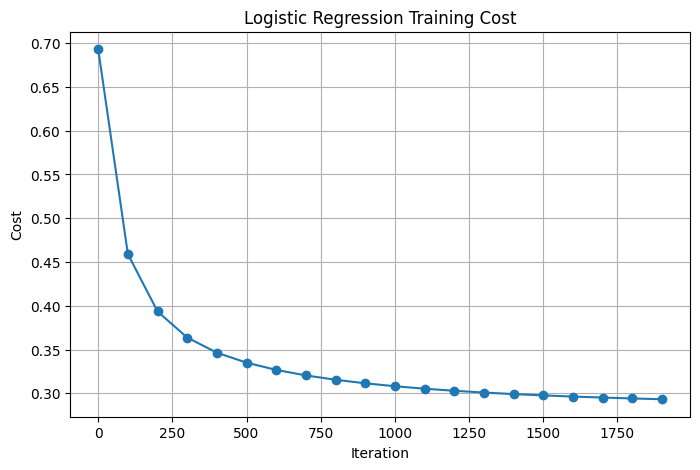


LOGISTIC REGRESSION RESULTS
Training Accuracy: 85.94%
Test Accuracy    : 83.75%


LEARNING RATE COMPARISON
Alpha = 0.001 Final Cost = 0.554181
Alpha = 0.01  Final Cost = 0.346469
Alpha = 0.05  Final Cost = 0.292413
Alpha = 0.5   Final Cost = 0.285280


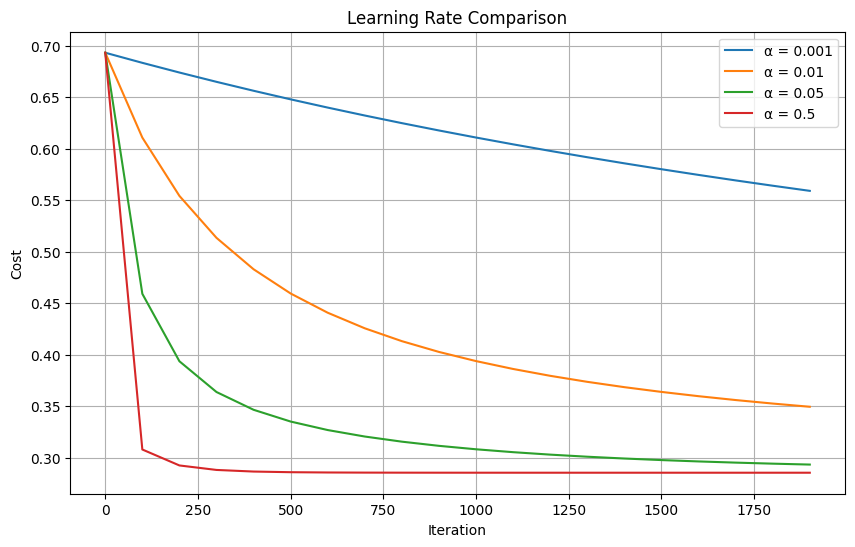



TASK 5 - TWO-LAYER NEURAL NETWORK

Two-Layer Network Training Complete!
Number of hidden neurons: 4
Final Cost: 0.07838704077721881


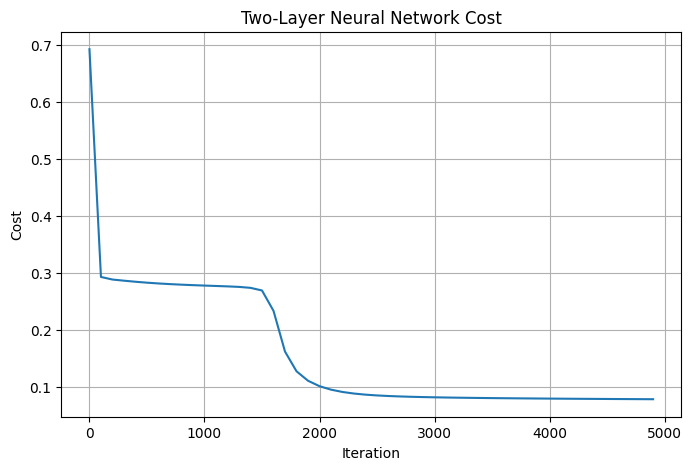


TWO-LAYER NETWORK RESULTS
Training Accuracy: 96.88%
Test Accuracy    : 93.75%


MODEL COMPARISON

Logistic Regression
-------------------
Training Accuracy: 85.94%
Test Accuracy    : 83.75%

Two-Layer Neural Network
------------------------
Training Accuracy: 96.88%
Test Accuracy    : 93.75%


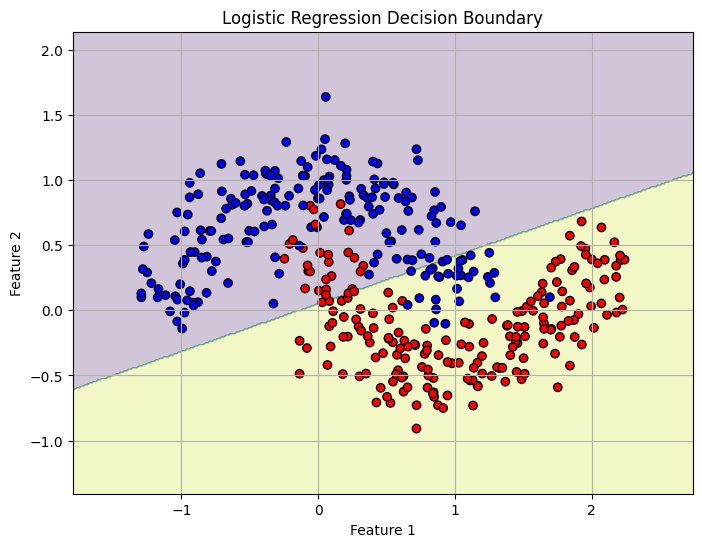

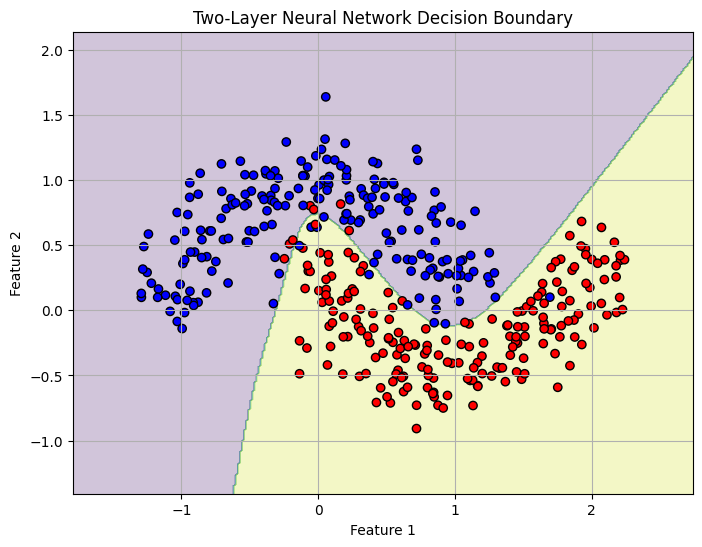



KEEPDIMS VERIFICATION

With keepdims=True
db2 shape: (1, 1)
db1 shape: (4, 1)

Without keepdims=True
db2 shape: (1,)
db1 shape: (4,)


FINAL SUMMARY

--- Logistic Regression ---
Final Cost: 0.292413
Train Accuracy: 85.94%
Test Accuracy: 83.75%

--- Two-Layer Neural Network ---
Hidden Neurons: 4
Final Cost: 0.078387
Train Accuracy: 96.88%
Test Accuracy: 93.75%

--- keepdims=True ---
db1 with keepdims: (4, 1)
db2 with keepdims: (1, 1)

--- keepdims=False ---
db1 without keepdims: (4,)
db2 without keepdims: (1,)

TASK 4 + TASK 5 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# DEEP LEARNING LAB
# TASK 4 + TASK 5
# Logistic Regression + Two-Layer Neural Network
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# ============================================================
# TASK 1 SUPPORT — DATASET
# ============================================================

print("Creating dataset...")

X_raw, y_raw = make_moons(
    n_samples=400,
    noise=0.20,
    random_state=1
)

# Required shape convention:
# X -> (n_features, m_examples)
# Y -> (1, m_examples)

X = X_raw.T
Y = y_raw.reshape(1, -1)

# ------------------------------------------------------------
# Train/Test Split
# ------------------------------------------------------------

m_train = 320

X_train = X[:, :m_train]
Y_train = Y[:, :m_train]

X_test = X[:, m_train:]
Y_test = Y[:, m_train:]

print("\nDataset Shapes")
print("----------------------------")
print("X       :", X.shape)
print("Y       :", Y.shape)
print("X_train :", X_train.shape)
print("Y_train :", Y_train.shape)
print("X_test  :", X_test.shape)
print("Y_test  :", Y_test.shape)


# ============================================================
# STABLE SIGMOID FUNCTION
# ============================================================

def sigmoid(z):

    z = np.asarray(z, dtype=float)

    # Handle positive and negative values separately
    # to avoid overflow in exp()

    positive = z >= 0
    negative = z < 0

    result = np.empty_like(z, dtype=float)

    # Positive values
    result[positive] = 1.0 / (
        1.0 + np.exp(-z[positive])
    )

    # Negative values
    exp_z = np.exp(z[negative])

    result[negative] = (
        exp_z / (1.0 + exp_z)
    )

    # Return scalar if scalar was supplied
    if result.ndim == 0:
        return float(result)

    return result


# Test sigmoid
print("\nSigmoid Tests")
print("----------------------------")
print("sigmoid(0)     =", sigmoid(0))
print("sigmoid(-1000) =", sigmoid(-1000))
print("sigmoid(1000)  =", sigmoid(1000))


# ============================================================
# PART A
# TASK 4 — LOGISTIC REGRESSION
# ============================================================

print("\n\n================================================")
print("TASK 4 - LOGISTIC REGRESSION")
print("================================================")


# ------------------------------------------------------------
# 1. Initialize Logistic Regression
# ------------------------------------------------------------

def initialize(n):

    w = np.zeros((n, 1))
    b = 0.0

    return w, b


# ------------------------------------------------------------
# 2. Forward Propagation
# ------------------------------------------------------------

def forward(w, b, X):

    Z = w.T @ X + b

    A = sigmoid(Z)

    assert A.shape == (1, X.shape[1])

    return A


# ------------------------------------------------------------
# 3. Cost Function
# ------------------------------------------------------------

def compute_cost(A, Y):

    m = Y.shape[1]

    # Numerical safety
    eps = 1e-8

    A_safe = np.clip(
        A,
        eps,
        1 - eps
    )

    cost = -(1 / m) * np.sum(
        Y * np.log(A_safe)
        +
        (1 - Y) * np.log(1 - A_safe)
    )

    return float(cost)


# ------------------------------------------------------------
# 4. Backward Propagation
# ------------------------------------------------------------

def backward(X, A, Y):

    m = X.shape[1]

    # Output error
    dZ = A - Y

    # Weight gradient
    dw = (1 / m) * (X @ dZ.T)

    # Bias gradient
    db = (1 / m) * np.sum(dZ)

    return dw, db


# ------------------------------------------------------------
# 5. Training Function
# ------------------------------------------------------------

def train(
    X,
    Y,
    iterations=2000,
    learning_rate=0.05
):

    n = X.shape[0]

    # Initialize
    w, b = initialize(n)

    costs = []
    cost_iterations = []

    for i in range(iterations):

        # -----------------------------
        # Forward propagation
        # -----------------------------

        A = forward(
            w,
            b,
            X
        )

        # -----------------------------
        # Cost
        # -----------------------------

        cost = compute_cost(
            A,
            Y
        )

        # -----------------------------
        # Backward propagation
        # -----------------------------

        dw, db = backward(
            X,
            A,
            Y
        )

        # -----------------------------
        # Gradient descent
        # -----------------------------

        w = w - learning_rate * dw

        b = b - learning_rate * db

        # -----------------------------
        # Record cost
        # -----------------------------

        if i % 100 == 0:

            costs.append(cost)
            cost_iterations.append(i)

    # Calculate final cost after final update
    A_final = forward(
        w,
        b,
        X
    )

    final_cost = compute_cost(
        A_final,
        Y
    )

    return (
        w,
        b,
        costs,
        cost_iterations,
        final_cost
    )


# ------------------------------------------------------------
# 6. Prediction Function
# ------------------------------------------------------------

def predict(w, b, X):

    A = forward(
        w,
        b,
        X
    )

    predictions = (
        A >= 0.5
    ).astype(int)

    return predictions


# ============================================================
# TRAIN LOGISTIC REGRESSION
# ============================================================

print("\nTraining Logistic Regression...")

(
    w_log,
    b_log,
    costs_log,
    iterations_log,
    final_cost_log
) = train(
    X_train,
    Y_train,
    iterations=2000,
    learning_rate=0.05
)


print("\nLogistic Regression Training Complete!")

print("\nFinal weights:")
print(w_log)

print("\nFinal bias:")
print(b_log)

print("\nFinal Cost:")
print(final_cost_log)


# ============================================================
# LOGISTIC REGRESSION COST PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    iterations_log,
    costs_log,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Logistic Regression Training Cost")

plt.grid(True)

plt.show()


# ============================================================
# LOGISTIC REGRESSION PREDICTIONS
# ============================================================

Y_train_pred = predict(
    w_log,
    b_log,
    X_train
)

Y_test_pred = predict(
    w_log,
    b_log,
    X_test
)


# ============================================================
# ACCURACY
# ============================================================

train_accuracy = (
    np.mean(
        Y_train_pred == Y_train
    ) * 100
)

test_accuracy = (
    np.mean(
        Y_test_pred == Y_test
    ) * 100
)


print("\n================================")
print("LOGISTIC REGRESSION RESULTS")
print("================================")

print(
    f"Training Accuracy: {train_accuracy:.2f}%"
)

print(
    f"Test Accuracy    : {test_accuracy:.2f}%"
)


# ============================================================
# LEARNING RATE COMPARISON
# ============================================================

print("\n\n================================")
print("LEARNING RATE COMPARISON")
print("================================")

learning_rates = [
    0.001,
    0.01,
    0.05,
    0.5
]

results_lr = {}


for alpha in learning_rates:

    (
        w_temp,
        b_temp,
        costs_temp,
        iterations_temp,
        final_cost_temp
    ) = train(
        X_train,
        Y_train,
        iterations=2000,
        learning_rate=alpha
    )

    results_lr[alpha] = {

        "w": w_temp,

        "b": b_temp,

        "costs": costs_temp,

        "iterations": iterations_temp,

        "final_cost": final_cost_temp
    }

    print(
        f"Alpha = {alpha:<5} "
        f"Final Cost = {final_cost_temp:.6f}"
    )


# ============================================================
# LEARNING RATE PLOT
# ============================================================

plt.figure(figsize=(10, 6))

for alpha in learning_rates:

    plt.plot(
        results_lr[alpha]["iterations"],
        results_lr[alpha]["costs"],
        label=f"α = {alpha}"
    )

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Learning Rate Comparison")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# PART B
# TASK 5 — TWO-LAYER NEURAL NETWORK
# ============================================================

print("\n\n================================================")
print("TASK 5 - TWO-LAYER NEURAL NETWORK")
print("================================================")


# ------------------------------------------------------------
# 7. Initialize Two-Layer Network
# ------------------------------------------------------------

def initialize_2layer(
    n_x,
    n_h,
    n_y
):

    W1 = (
        np.random.randn(
            n_h,
            n_x
        ) * 0.01
    )

    b1 = np.zeros(
        (n_h, 1)
    )

    W2 = (
        np.random.randn(
            n_y,
            n_h
        ) * 0.01
    )

    b2 = np.zeros(
        (n_y, 1)
    )

    return W1, b1, W2, b2


# ------------------------------------------------------------
# 8. Forward Propagation
# ------------------------------------------------------------

def forward_2layer(
    params,
    X
):

    W1, b1, W2, b2 = params

    # Hidden layer
    Z1 = W1 @ X + b1

    A1 = np.tanh(Z1)

    # Output layer
    Z2 = W2 @ A1 + b2

    A2 = sigmoid(Z2)

    return (
        Z1,
        A1,
        Z2,
        A2
    )


# ------------------------------------------------------------
# 9. Cost Function
# ------------------------------------------------------------

def compute_cost_2layer(
    A2,
    Y
):

    m = Y.shape[1]

    eps = 1e-8

    A2_safe = np.clip(
        A2,
        eps,
        1 - eps
    )

    cost = -(1 / m) * np.sum(
        Y * np.log(A2_safe)
        +
        (1 - Y) * np.log(1 - A2_safe)
    )

    return float(cost)


# ------------------------------------------------------------
# 10. Backward Propagation
# ------------------------------------------------------------

def backward_2layer(
    params,
    X,
    Y
):

    W1, b1, W2, b2 = params

    m = X.shape[1]

    # Forward pass
    (
        Z1,
        A1,
        Z2,
        A2
    ) = forward_2layer(
        params,
        X
    )

    # --------------------------------
    # Output layer
    # --------------------------------

    dZ2 = A2 - Y

    dW2 = (
        (1 / m)
        *
        (dZ2 @ A1.T)
    )

    db2 = (
        (1 / m)
        *
        np.sum(
            dZ2,
            axis=1,
            keepdims=True
        )
    )

    # --------------------------------
    # Hidden layer
    # --------------------------------

    dZ1 = (
        (W2.T @ dZ2)
        *
        (1 - A1 ** 2)
    )

    dW1 = (
        (1 / m)
        *
        (dZ1 @ X.T)
    )

    db1 = (
        (1 / m)
        *
        np.sum(
            dZ1,
            axis=1,
            keepdims=True
        )
    )

    grads = {

        "dW1": dW1,

        "db1": db1,

        "dW2": dW2,

        "db2": db2
    }

    return grads


# ------------------------------------------------------------
# 11. Update Parameters
# ------------------------------------------------------------

def update_2layer(
    params,
    grads,
    learning_rate
):

    W1, b1, W2, b2 = params

    W1 = (
        W1
        -
        learning_rate * grads["dW1"]
    )

    b1 = (
        b1
        -
        learning_rate * grads["db1"]
    )

    W2 = (
        W2
        -
        learning_rate * grads["dW2"]
    )

    b2 = (
        b2
        -
        learning_rate * grads["db2"]
    )

    return (
        W1,
        b1,
        W2,
        b2
    )


# ------------------------------------------------------------
# 12. Train Two-Layer Network
# ------------------------------------------------------------

def train_2layer(
    X,
    Y,
    n_h=4,
    iterations=5000,
    learning_rate=0.5
):

    n_x = X.shape[0]

    n_y = 1

    # Reproducible initialization
    np.random.seed(1)

    (
        W1,
        b1,
        W2,
        b2
    ) = initialize_2layer(
        n_x,
        n_h,
        n_y
    )

    params = (
        W1,
        b1,
        W2,
        b2
    )

    costs = []
    cost_iterations = []

    for i in range(iterations):

        # -----------------------------
        # Forward
        # -----------------------------

        (
            Z1,
            A1,
            Z2,
            A2
        ) = forward_2layer(
            params,
            X
        )

        # -----------------------------
        # Cost
        # -----------------------------

        cost = compute_cost_2layer(
            A2,
            Y
        )

        # -----------------------------
        # Backward
        # -----------------------------

        grads = backward_2layer(
            params,
            X,
            Y
        )

        # -----------------------------
        # Update
        # -----------------------------

        params = update_2layer(
            params,
            grads,
            learning_rate
        )

        # -----------------------------
        # Record cost
        # -----------------------------

        if i % 100 == 0:

            costs.append(cost)
            cost_iterations.append(i)

    # Final cost
    (
        Z1,
        A1,
        Z2,
        A2
    ) = forward_2layer(
        params,
        X
    )

    final_cost = compute_cost_2layer(
        A2,
        Y
    )

    return (
        params,
        costs,
        cost_iterations,
        final_cost
    )


# ============================================================
# TRAIN TWO-LAYER NETWORK
# ============================================================

n_h = 4

(
    params_nn,
    costs_nn,
    iterations_nn,
    final_cost_nn
) = train_2layer(
    X_train,
    Y_train,
    n_h=n_h,
    iterations=5000,
    learning_rate=0.5
)


print("\nTwo-Layer Network Training Complete!")

print(
    "Number of hidden neurons:",
    n_h
)

print(
    "Final Cost:",
    final_cost_nn
)


# ============================================================
# NEURAL NETWORK COST PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    iterations_nn,
    costs_nn
)

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Two-Layer Neural Network Cost")

plt.grid(True)

plt.show()


# ============================================================
# 13. NEURAL NETWORK PREDICTION
# ============================================================

def predict_2layer(
    params,
    X
):

    (
        Z1,
        A1,
        Z2,
        A2
    ) = forward_2layer(
        params,
        X
    )

    predictions = (
        A2 >= 0.5
    ).astype(int)

    return predictions


# ============================================================
# 14. NEURAL NETWORK ACCURACY
# ============================================================

Y_train_pred_nn = predict_2layer(
    params_nn,
    X_train
)

Y_test_pred_nn = predict_2layer(
    params_nn,
    X_test
)


train_accuracy_nn = (
    np.mean(
        Y_train_pred_nn == Y_train
    ) * 100
)

test_accuracy_nn = (
    np.mean(
        Y_test_pred_nn == Y_test
    ) * 100
)


print("\n================================")
print("TWO-LAYER NETWORK RESULTS")
print("================================")

print(
    f"Training Accuracy: {train_accuracy_nn:.2f}%"
)

print(
    f"Test Accuracy    : {test_accuracy_nn:.2f}%"
)


# ============================================================
# MODEL COMPARISON
# ============================================================

print("\n\n================================")
print("MODEL COMPARISON")
print("================================")

print("\nLogistic Regression")
print("-------------------")

print(
    f"Training Accuracy: {train_accuracy:.2f}%"
)

print(
    f"Test Accuracy    : {test_accuracy:.2f}%"
)

print("\nTwo-Layer Neural Network")
print("------------------------")

print(
    f"Training Accuracy: {train_accuracy_nn:.2f}%"
)

print(
    f"Test Accuracy    : {test_accuracy_nn:.2f}%"
)


# ============================================================
# PART C
# DECISION BOUNDARIES
# ============================================================


# ------------------------------------------------------------
# 15. Logistic Regression Decision Boundary
# ------------------------------------------------------------

def plot_logistic_boundary(
    w,
    b,
    X,
    Y,
    title
):

    x_min = X[0].min() - 0.5
    x_max = X[0].max() + 0.5

    y_min = X[1].min() - 0.5
    y_max = X[1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(
            x_min,
            x_max,
            300
        ),
        np.linspace(
            y_min,
            y_max,
            300
        )
    )

    grid = np.vstack(
        [
            xx.ravel(),
            yy.ravel()
        ]
    )

    Z = predict(
        w,
        b,
        grid
    )

    Z = Z.reshape(
        xx.shape
    )

    plt.figure(
        figsize=(8, 6)
    )

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.25
    )

    plt.scatter(
        X[0],
        X[1],
        c=Y.ravel(),
        cmap="bwr",
        edgecolors="k"
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)

    plt.grid(True)

    plt.show()


# ------------------------------------------------------------
# 16. Neural Network Decision Boundary
# ------------------------------------------------------------

def plot_nn_boundary(
    params,
    X,
    Y,
    title
):

    x_min = X[0].min() - 0.5
    x_max = X[0].max() + 0.5

    y_min = X[1].min() - 0.5
    y_max = X[1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(
            x_min,
            x_max,
            300
        ),
        np.linspace(
            y_min,
            y_max,
            300
        )
    )

    grid = np.vstack(
        [
            xx.ravel(),
            yy.ravel()
        ]
    )

    Z = predict_2layer(
        params,
        grid
    )

    Z = Z.reshape(
        xx.shape
    )

    plt.figure(
        figsize=(8, 6)
    )

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.25
    )

    plt.scatter(
        X[0],
        X[1],
        c=Y.ravel(),
        cmap="bwr",
        edgecolors="k"
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)

    plt.grid(True)

    plt.show()


# ============================================================
# PLOT DECISION BOUNDARIES
# ============================================================

plot_logistic_boundary(
    w_log,
    b_log,
    X,
    Y,
    "Logistic Regression Decision Boundary"
)

plot_nn_boundary(
    params_nn,
    X,
    Y,
    "Two-Layer Neural Network Decision Boundary"
)


# ============================================================
# PART D
# VERIFY keepdims=True
# ============================================================

print("\n\n================================")
print("KEEPDIMS VERIFICATION")
print("================================")


# Get parameters
W1, b1, W2, b2 = params_nn


# Forward pass
(
    Z1,
    A1,
    Z2,
    A2
) = forward_2layer(
    params_nn,
    X_train
)

m = X_train.shape[1]


# ------------------------------------------------------------
# With keepdims=True
# ------------------------------------------------------------

dZ2 = A2 - Y_train

db2_keep = (
    (1 / m)
    *
    np.sum(
        dZ2,
        axis=1,
        keepdims=True
    )
)

dZ1 = (
    (W2.T @ dZ2)
    *
    (1 - A1 ** 2)
)

db1_keep = (
    (1 / m)
    *
    np.sum(
        dZ1,
        axis=1,
        keepdims=True
    )
)


print("\nWith keepdims=True")

print(
    "db2 shape:",
    db2_keep.shape
)

print(
    "db1 shape:",
    db1_keep.shape
)


# ------------------------------------------------------------
# Without keepdims=True
# ------------------------------------------------------------

db2_no_keep = (
    (1 / m)
    *
    np.sum(
        dZ2,
        axis=1
    )
)

db1_no_keep = (
    (1 / m)
    *
    np.sum(
        dZ1,
        axis=1
    )
)


print("\nWithout keepdims=True")

print(
    "db2 shape:",
    db2_no_keep.shape
)

print(
    "db1 shape:",
    db1_no_keep.shape
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n\n============================================")
print("FINAL SUMMARY")
print("============================================")

print("\n--- Logistic Regression ---")

print(
    f"Final Cost: {final_cost_log:.6f}"
)

print(
    f"Train Accuracy: {train_accuracy:.2f}%"
)

print(
    f"Test Accuracy: {test_accuracy:.2f}%"
)


print("\n--- Two-Layer Neural Network ---")

print(
    "Hidden Neurons:",
    n_h
)

print(
    f"Final Cost: {final_cost_nn:.6f}"
)

print(
    f"Train Accuracy: {train_accuracy_nn:.2f}%"
)

print(
    f"Test Accuracy: {test_accuracy_nn:.2f}%"
)


print("\n--- keepdims=True ---")

print(
    "db1 with keepdims:",
    db1_keep.shape
)

print(
    "db2 with keepdims:",
    db2_keep.shape
)


print("\n--- keepdims=False ---")

print(
    "db1 without keepdims:",
    db1_no_keep.shape
)

print(
    "db2 without keepdims:",
    db2_no_keep.shape
)


print("\n============================================")
print("TASK 4 + TASK 5 COMPLETED SUCCESSFULLY")
print("============================================")

X_train shape: (2, 320)
Y_train shape: (1, 320)
X_test shape : (2, 80)
Y_test shape : (1, 80)


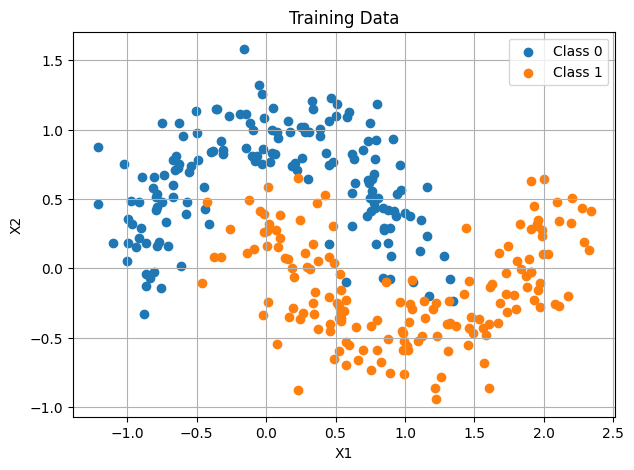



TRAINING WITH LEARNING RATE = 0.05
Iteration    0 | Cost = 0.693147
Iteration  100 | Cost = 0.468602
Iteration  200 | Cost = 0.403421
Iteration  300 | Cost = 0.373369
Iteration  400 | Cost = 0.356039
Iteration  500 | Cost = 0.344650
Iteration  600 | Cost = 0.336528
Iteration  700 | Cost = 0.330422
Iteration  800 | Cost = 0.325664
Iteration  900 | Cost = 0.321863
Iteration 1000 | Cost = 0.318770
Iteration 1100 | Cost = 0.316220
Iteration 1200 | Cost = 0.314095
Iteration 1300 | Cost = 0.312309
Iteration 1400 | Cost = 0.310796
Iteration 1500 | Cost = 0.309509
Iteration 1600 | Cost = 0.308406
Iteration 1700 | Cost = 0.307458
Iteration 1800 | Cost = 0.306639
Iteration 1900 | Cost = 0.305929


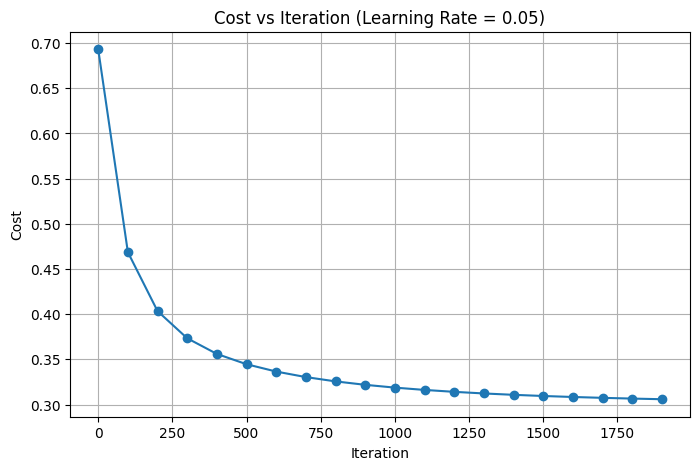



MODEL EVALUATION
Training Accuracy: 86.25%
Test Accuracy:     91.25%


TRAINING WITH α = 0.001
Iteration    0 | Cost = 0.693147
Iteration  100 | Cost = 0.683857
Iteration  200 | Cost = 0.674943
Iteration  300 | Cost = 0.666386
Iteration  400 | Cost = 0.658168
Iteration  500 | Cost = 0.650270
Iteration  600 | Cost = 0.642677
Iteration  700 | Cost = 0.635372
Iteration  800 | Cost = 0.628340
Iteration  900 | Cost = 0.621569
Iteration 1000 | Cost = 0.615045
Iteration 1100 | Cost = 0.608755
Iteration 1200 | Cost = 0.602688
Iteration 1300 | Cost = 0.596832
Iteration 1400 | Cost = 0.591179
Iteration 1500 | Cost = 0.585717
Iteration 1600 | Cost = 0.580438
Iteration 1700 | Cost = 0.575334
Iteration 1800 | Cost = 0.570395
Iteration 1900 | Cost = 0.565615


TRAINING WITH α = 0.01
Iteration    0 | Cost = 0.693147
Iteration  100 | Cost = 0.614991
Iteration  200 | Cost = 0.560918
Iteration  300 | Cost = 0.521641
Iteration  400 | Cost = 0.491976
Iteration  500 | Cost = 0.468874
Iteration  600 | Cos

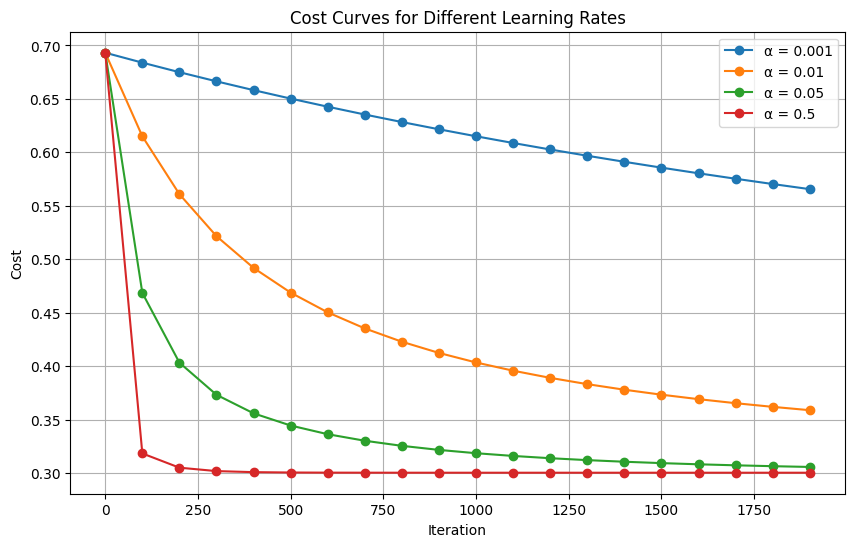



FINAL COST COMPARISON
α = 0.001 Final Cost = 0.565615
α = 0.01  Final Cost = 0.358977
α = 0.05  Final Cost = 0.305929
α = 0.5   Final Cost = 0.300532


In [2]:
# ============================================================
# TASK 4 — TRAINING LOOP AND EVALUATION
# Logistic Regression From Scratch
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PART 1 — CREATE THE MAKE-MOONS DATASET
# ============================================================
# We create the dataset manually so sklearn is NOT required.

np.random.seed(1)

m = 400

# Number of samples for each class
m0 = m // 2
m1 = m - m0

# Class 0
theta0 = np.linspace(0, np.pi, m0)

x0 = np.cos(theta0)
y0 = np.sin(theta0)

# Add noise
x0 = x0 + 0.20 * np.random.randn(m0)
y0 = y0 + 0.20 * np.random.randn(m0)


# Class 1
theta1 = np.linspace(0, np.pi, m1)

x1 = 1 - np.cos(theta1)
y1 = 0.5 - np.sin(theta1)

# Add noise
x1 = x1 + 0.20 * np.random.randn(m1)
y1 = y1 + 0.20 * np.random.randn(m1)


# Combine data
X = np.vstack([
    np.concatenate([x0, x1]),
    np.concatenate([y0, y1])
])

Y = np.concatenate([
    np.zeros(m0),
    np.ones(m1)
]).reshape(1, m)


# ============================================================
# SHUFFLE DATA
# ============================================================

indices = np.random.permutation(m)

X = X[:, indices]
Y = Y[:, indices]


# ============================================================
# TRAIN / TEST SPLIT
# 320 training samples
# 80 testing samples
# ============================================================

X_train = X[:, :320]
Y_train = Y[:, :320]

X_test = X[:, 320:]
Y_test = Y[:, 320:]


# ============================================================
# CHECK SHAPES
# ============================================================

print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)
print("X_test shape :", X_test.shape)
print("Y_test shape :", Y_test.shape)


# ============================================================
# VISUALIZE DATA
# ============================================================

plt.figure(figsize=(7, 5))

plt.scatter(
    X_train[0, Y_train[0] == 0],
    X_train[1, Y_train[0] == 0],
    label="Class 0"
)

plt.scatter(
    X_train[0, Y_train[0] == 1],
    X_train[1, Y_train[0] == 1],
    label="Class 1"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Training Data")
plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# PART 2 — SIGMOID FUNCTION
# ============================================================

def sigmoid(z):

    z = np.asarray(z)

    result = np.empty_like(z, dtype=float)

    positive = z >= 0
    negative = ~positive

    result[positive] = 1 / (1 + np.exp(-z[positive]))

    exp_z = np.exp(z[negative])

    result[negative] = exp_z / (1 + exp_z)

    return result


# ============================================================
# PART 3 — FORWARD PROPAGATION
# ============================================================

def forward(w, b, X):

    Z = np.dot(w.T, X) + b

    A = sigmoid(Z)

    return A


# ============================================================
# PART 4 — COST FUNCTION
# ============================================================

def compute_cost(A, Y):

    m = Y.shape[1]

    epsilon = 1e-15

    A = np.clip(A, epsilon, 1 - epsilon)

    cost = -(1 / m) * np.sum(
        Y * np.log(A)
        +
        (1 - Y) * np.log(1 - A)
    )

    return cost


# ============================================================
# PART 5 — BACKWARD PROPAGATION
# ============================================================

def backward(w, b, X, Y):

    m = X.shape[1]

    # Forward propagation
    A = forward(w, b, X)

    # Gradient
    dZ = A - Y

    dw = (1 / m) * np.dot(X, dZ.T)

    db = (1 / m) * np.sum(dZ)

    return dw, db


# ============================================================
# PART 6 — UPDATE PARAMETERS
# ============================================================

def update(w, b, dw, db, learning_rate):

    w = w - learning_rate * dw

    b = b - learning_rate * db

    return w, b


# ============================================================
# PART 7 — TRAINING FUNCTION
# ============================================================

def train(X, Y, iterations, learning_rate):

    n_features = X.shape[0]

    # Initialize parameters
    w = np.zeros((n_features, 1))
    b = 0.0

    costs = []
    cost_iters = []

    # Training loop
    for i in range(iterations):

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        A = forward(w, b, X)

        # ----------------------------------------------------
        # Cost
        # ----------------------------------------------------

        cost = compute_cost(A, Y)

        # ----------------------------------------------------
        # Backward
        # ----------------------------------------------------

        dw, db = backward(w, b, X, Y)

        # ----------------------------------------------------
        # Update
        # ----------------------------------------------------

        w, b = update(
            w,
            b,
            dw,
            db,
            learning_rate
        )

        # ----------------------------------------------------
        # Record cost every 100 iterations
        # ----------------------------------------------------

        if i % 100 == 0:

            costs.append(cost)
            cost_iters.append(i)

            print(
                f"Iteration {i:4d} | Cost = {cost:.6f}"
            )

    return w, b, costs, cost_iters


# ============================================================
# PART 8 — PREDICTION FUNCTION
# ============================================================

def predict(w, b, X):

    # Get probabilities
    A = forward(w, b, X)

    # Threshold = 0.5
    predictions = (A >= 0.5).astype(int)

    return predictions


# ============================================================
# PART 9 — ACCURACY FUNCTION
# ============================================================

def calculate_accuracy(Y_true, Y_pred):

    accuracy = np.mean(Y_true == Y_pred) * 100

    return accuracy


# ============================================================
# PART 10 — TRAIN MODEL
# 2000 ITERATIONS
# LEARNING RATE = 0.05
# ============================================================

print("\n")
print("==========================================")
print("TRAINING WITH LEARNING RATE = 0.05")
print("==========================================")


w, b, costs, cost_iters = train(
    X_train,
    Y_train,
    iterations=2000,
    learning_rate=0.05
)


# ============================================================
# PART 11 — PLOT COST
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    cost_iters,
    costs,
    marker='o'
)

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.title(
    "Cost vs Iteration (Learning Rate = 0.05)"
)

plt.grid(True)

plt.show()


# ============================================================
# PART 12 — PREDICTIONS
# ============================================================

train_predictions = predict(
    w,
    b,
    X_train
)

test_predictions = predict(
    w,
    b,
    X_test
)


# ============================================================
# PART 13 — ACCURACY
# ============================================================

train_accuracy = calculate_accuracy(
    Y_train,
    train_predictions
)

test_accuracy = calculate_accuracy(
    Y_test,
    test_predictions
)


print("\n")
print("==========================================")
print("MODEL EVALUATION")
print("==========================================")

print(
    f"Training Accuracy: {train_accuracy:.2f}%"
)

print(
    f"Test Accuracy:     {test_accuracy:.2f}%"
)


# ============================================================
# PART 14 — DIFFERENT LEARNING RATES
# ============================================================

learning_rates = [
    0.001,
    0.01,
    0.05,
    0.5
]

all_costs = {}


for alpha in learning_rates:

    print("\n")
    print("==========================================")
    print(f"TRAINING WITH α = {alpha}")
    print("==========================================")

    w_temp, b_temp, costs_temp, iters_temp = train(
        X_train,
        Y_train,
        iterations=2000,
        learning_rate=alpha
    )

    all_costs[alpha] = (
        iters_temp,
        costs_temp
    )


# ============================================================
# PART 15 — PLOT ALL FOUR COST CURVES
# ============================================================

plt.figure(figsize=(10, 6))

for alpha in learning_rates:

    iterations_plot = all_costs[alpha][0]

    costs_plot = all_costs[alpha][1]

    plt.plot(
        iterations_plot,
        costs_plot,
        marker='o',
        label=f"α = {alpha}"
    )


plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.title(
    "Cost Curves for Different Learning Rates"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# PART 16 — FINAL COST COMPARISON
# ============================================================

print("\n")
print("==========================================")
print("FINAL COST COMPARISON")
print("==========================================")

for alpha in learning_rates:

    final_cost = all_costs[alpha][1][-1]

    print(
        f"α = {alpha:<5} "
        f"Final Cost = {final_cost:.6f}"
    )

X_train: (2, 320)
Y_train: (1, 320)
X_test : (2, 80)
Y_test : (1, 80)


TWO-LAYER NEURAL NETWORK
Iteration    0 | Cost = 0.692995
Iteration  500 | Cost = 0.304330
Iteration 1000 | Cost = 0.302836
Iteration 1500 | Cost = 0.301913
Iteration 2000 | Cost = 0.300695
Iteration 2500 | Cost = 0.296915
Iteration 3000 | Cost = 0.108400
Iteration 3500 | Cost = 0.096248
Iteration 4000 | Cost = 0.092458
Iteration 4500 | Cost = 0.090250


NEURAL NETWORK RESULTS
Training Accuracy: 96.88%
Test Accuracy: 95.00%


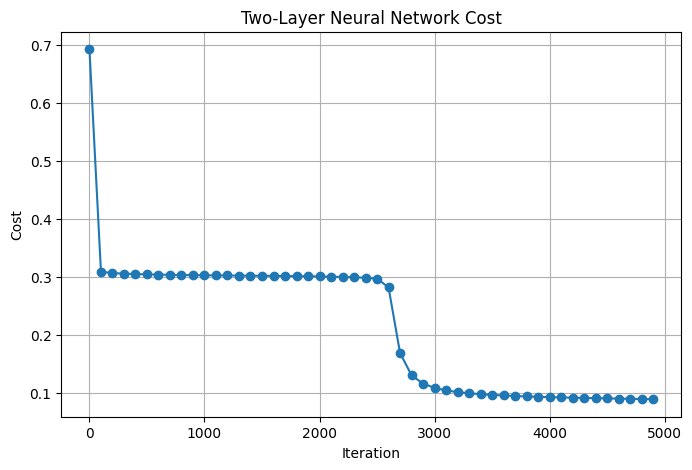



MODEL COMPARISON

Logistic Regression:
Training Accuracy: 86.25%
Test Accuracy: 91.25%

Two-Layer Neural Network:
Training Accuracy: 96.88%
Test Accuracy: 95.00%


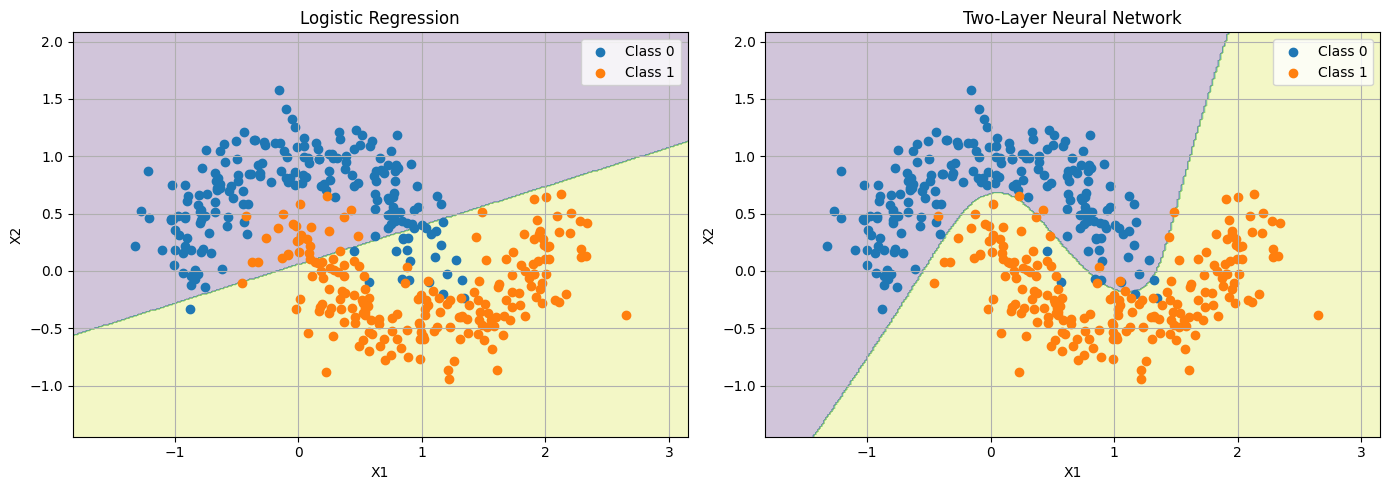



KEEPDIMS VERIFICATION
Correct db2 shape with keepdims=True: (1, 1)
db2 shape without keepdims=True: (1,)
Correct db1 shape with keepdims=True: (4, 1)
db1 shape without keepdims=True: (4,)


In [3]:
# ============================================================
# TASK 5 — TWO-LAYER NEURAL NETWORK
# One Hidden Layer + Tanh + Sigmoid
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PART 1 — CREATE DATASET
# ============================================================
# 400 samples
# 320 training
# 80 testing
# No sklearn required

np.random.seed(1)

m = 400

# -----------------------------
# Class 0
# -----------------------------

m0 = m // 2

theta0 = np.linspace(0, np.pi, m0)

x0 = np.cos(theta0)
y0 = np.sin(theta0)

x0 = x0 + 0.20 * np.random.randn(m0)
y0 = y0 + 0.20 * np.random.randn(m0)


# -----------------------------
# Class 1
# -----------------------------

m1 = m - m0

theta1 = np.linspace(0, np.pi, m1)

x1 = 1 - np.cos(theta1)
y1 = 0.5 - np.sin(theta1)

x1 = x1 + 0.20 * np.random.randn(m1)
y1 = y1 + 0.20 * np.random.randn(m1)


# -----------------------------
# Combine
# -----------------------------

X = np.vstack([
    np.concatenate([x0, x1]),
    np.concatenate([y0, y1])
])

Y = np.concatenate([
    np.zeros(m0),
    np.ones(m1)
]).reshape(1, m)


# ============================================================
# SHUFFLE DATA
# ============================================================

indices = np.random.permutation(m)

X = X[:, indices]
Y = Y[:, indices]


# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train = X[:, :320]
Y_train = Y[:, :320]

X_test = X[:, 320:]
Y_test = Y[:, 320:]


print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test :", X_test.shape)
print("Y_test :", Y_test.shape)


# ============================================================
# PART 2 — SIGMOID
# ============================================================

def sigmoid(z):

    z = np.asarray(z)

    result = np.empty_like(z, dtype=float)

    positive = z >= 0
    negative = ~positive

    result[positive] = 1 / (1 + np.exp(-z[positive]))

    exp_z = np.exp(z[negative])

    result[negative] = exp_z / (1 + exp_z)

    return result


# ============================================================
# PART 3 — COST FUNCTION
# ============================================================

def compute_cost(A2, Y):

    m = Y.shape[1]

    epsilon = 1e-15

    A2 = np.clip(A2, epsilon, 1 - epsilon)

    cost = -(1 / m) * np.sum(
        Y * np.log(A2)
        +
        (1 - Y) * np.log(1 - A2)
    )

    return cost


# ============================================================
# PART 4 — INITIALIZE TWO-LAYER NETWORK
# ============================================================

def initialize_2layer(n_x, n_h, n_y):

    np.random.seed(2)

    W1 = np.random.randn(n_h, n_x) * 0.01
    b1 = np.zeros((n_h, 1))

    W2 = np.random.randn(n_y, n_h) * 0.01
    b2 = np.zeros((n_y, 1))

    parameters = {
        "W1": W1,
        "b1": b1,
        "W2": W2,
        "b2": b2
    }

    return parameters


# ============================================================
# PART 5 — FORWARD PROPAGATION
# ============================================================

def forward_2layer(X, parameters):

    W1 = parameters["W1"]
    b1 = parameters["b1"]

    W2 = parameters["W2"]
    b2 = parameters["b2"]

    # Hidden layer
    Z1 = W1 @ X + b1

    A1 = np.tanh(Z1)

    # Output layer
    Z2 = W2 @ A1 + b2

    A2 = sigmoid(Z2)

    cache = {
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2
    }

    return A2, cache


# ============================================================
# PART 6 — BACKWARD PROPAGATION
# ============================================================

def backward_2layer(X, Y, parameters, cache):

    W2 = parameters["W2"]

    A1 = cache["A1"]
    A2 = cache["A2"]

    m = X.shape[1]

    # --------------------------------------------------------
    # Output layer gradient
    # --------------------------------------------------------

    dZ2 = A2 - Y

    dW2 = (1 / m) * (dZ2 @ A1.T)

    db2 = (1 / m) * np.sum(
        dZ2,
        axis=1,
        keepdims=True
    )

    # --------------------------------------------------------
    # Hidden layer gradient
    # --------------------------------------------------------

    dZ1 = (W2.T @ dZ2) * (
        1 - np.power(A1, 2)
    )

    dW1 = (1 / m) * (dZ1 @ X.T)

    db1 = (1 / m) * np.sum(
        dZ1,
        axis=1,
        keepdims=True
    )

    grads = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2
    }

    return grads


# ============================================================
# PART 7 — UPDATE PARAMETERS
# ============================================================

def update_2layer(parameters, grads, learning_rate):

    parameters["W1"] = (
        parameters["W1"]
        - learning_rate * grads["dW1"]
    )

    parameters["b1"] = (
        parameters["b1"]
        - learning_rate * grads["db1"]
    )

    parameters["W2"] = (
        parameters["W2"]
        - learning_rate * grads["dW2"]
    )

    parameters["b2"] = (
        parameters["b2"]
        - learning_rate * grads["db2"]
    )

    return parameters


# ============================================================
# PART 8 — TRAIN TWO-LAYER NETWORK
# ============================================================

def train_2layer(
    X,
    Y,
    n_h,
    iterations,
    learning_rate
):

    n_x = X.shape[0]
    n_y = Y.shape[0]

    # Initialize
    parameters = initialize_2layer(
        n_x,
        n_h,
        n_y
    )

    costs = []
    cost_iters = []

    # Training loop
    for i in range(iterations):

        # -------------------------
        # Forward
        # -------------------------

        A2, cache = forward_2layer(
            X,
            parameters
        )

        # -------------------------
        # Cost
        # -------------------------

        cost = compute_cost(
            A2,
            Y
        )

        # -------------------------
        # Backward
        # -------------------------

        grads = backward_2layer(
            X,
            Y,
            parameters,
            cache
        )

        # -------------------------
        # Update
        # -------------------------

        parameters = update_2layer(
            parameters,
            grads,
            learning_rate
        )

        # -------------------------
        # Record cost
        # -------------------------

        if i % 100 == 0:

            costs.append(cost)
            cost_iters.append(i)

            if i % 500 == 0:
                print(
                    f"Iteration {i:4d} | "
                    f"Cost = {cost:.6f}"
                )

    return parameters, costs, cost_iters


# ============================================================
# PART 9 — PREDICTION
# ============================================================

def predict_2layer(X, parameters):

    A2, cache = forward_2layer(
        X,
        parameters
    )

    predictions = (
        A2 >= 0.5
    ).astype(int)

    return predictions


# ============================================================
# PART 10 — ACCURACY
# ============================================================

def calculate_accuracy(Y_true, Y_pred):

    return np.mean(
        Y_true == Y_pred
    ) * 100


# ============================================================
# PART 11 — TRAIN NETWORK
# n_h = 4
# 5000 ITERATIONS
# alpha = 0.5
# ============================================================

print("\n")
print("==========================================")
print("TWO-LAYER NEURAL NETWORK")
print("==========================================")

parameters, nn_costs, nn_iters = train_2layer(
    X_train,
    Y_train,
    n_h=4,
    iterations=5000,
    learning_rate=0.5
)


# ============================================================
# PART 12 — NEURAL NETWORK ACCURACY
# ============================================================

nn_train_predictions = predict_2layer(
    X_train,
    parameters
)

nn_test_predictions = predict_2layer(
    X_test,
    parameters
)


nn_train_accuracy = calculate_accuracy(
    Y_train,
    nn_train_predictions
)

nn_test_accuracy = calculate_accuracy(
    Y_test,
    nn_test_predictions
)


print("\n")
print("==========================================")
print("NEURAL NETWORK RESULTS")
print("==========================================")

print(
    f"Training Accuracy: "
    f"{nn_train_accuracy:.2f}%"
)

print(
    f"Test Accuracy: "
    f"{nn_test_accuracy:.2f}%"
)


# ============================================================
# PART 13 — PLOT NEURAL NETWORK COST
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    nn_iters,
    nn_costs,
    marker='o'
)

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.title(
    "Two-Layer Neural Network Cost"
)

plt.grid(True)

plt.show()


# ============================================================
# PART 14 — LOGISTIC REGRESSION FOR COMPARISON
# ============================================================

def logistic_forward(w, b, X):

    Z = w.T @ X + b

    return sigmoid(Z)


def logistic_backward(w, b, X, Y):

    m = X.shape[1]

    A = logistic_forward(
        w,
        b,
        X
    )

    dZ = A - Y

    dw = (1 / m) * (X @ dZ.T)

    db = (1 / m) * np.sum(dZ)

    return dw, db


def train_logistic(
    X,
    Y,
    iterations,
    learning_rate
):

    n_x = X.shape[0]

    w = np.zeros(
        (n_x, 1)
    )

    b = 0.0

    costs = []
    cost_iters = []

    for i in range(iterations):

        A = logistic_forward(
            w,
            b,
            X
        )

        cost = compute_cost(
            A,
            Y
        )

        dw, db = logistic_backward(
            w,
            b,
            X,
            Y
        )

        w = w - learning_rate * dw

        b = b - learning_rate * db

        if i % 100 == 0:

            costs.append(cost)
            cost_iters.append(i)

    return w, b, costs, cost_iters


def predict_logistic(w, b, X):

    A = logistic_forward(
        w,
        b,
        X
    )

    return (
        A >= 0.5
    ).astype(int)


# Train logistic regression
logistic_w, logistic_b, logistic_costs, logistic_iters = train_logistic(
    X_train,
    Y_train,
    iterations=2000,
    learning_rate=0.05
)


# Logistic predictions
logistic_train_pred = predict_logistic(
    logistic_w,
    logistic_b,
    X_train
)

logistic_test_pred = predict_logistic(
    logistic_w,
    logistic_b,
    X_test
)


logistic_train_accuracy = calculate_accuracy(
    Y_train,
    logistic_train_pred
)

logistic_test_accuracy = calculate_accuracy(
    Y_test,
    logistic_test_pred
)


# ============================================================
# PART 15 — COMPARE BOTH MODELS
# ============================================================

print("\n")
print("==========================================")
print("MODEL COMPARISON")
print("==========================================")

print("\nLogistic Regression:")
print(
    f"Training Accuracy: "
    f"{logistic_train_accuracy:.2f}%"
)

print(
    f"Test Accuracy: "
    f"{logistic_test_accuracy:.2f}%"
)


print("\nTwo-Layer Neural Network:")

print(
    f"Training Accuracy: "
    f"{nn_train_accuracy:.2f}%"
)

print(
    f"Test Accuracy: "
    f"{nn_test_accuracy:.2f}%"
)


# ============================================================
# PART 16 — DECISION BOUNDARY FUNCTION
# ============================================================

def plot_decision_boundary(
    predict_function,
    X,
    Y,
    title,
    ax
):

    # Create grid
    x_min = X[0, :].min() - 0.5
    x_max = X[0, :].max() + 0.5

    y_min = X[1, :].min() - 0.5
    y_max = X[1, :].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[
        xx.ravel(),
        yy.ravel()
    ].T

    predictions = predict_function(
        grid
    )

    predictions = predictions.reshape(
        xx.shape
    )

    # Decision regions
    ax.contourf(
        xx,
        yy,
        predictions,
        alpha=0.25
    )

    # Class 0
    ax.scatter(
        X[0, Y[0] == 0],
        X[1, Y[0] == 0],
        label="Class 0"
    )

    # Class 1
    ax.scatter(
        X[0, Y[0] == 1],
        X[1, Y[0] == 1],
        label="Class 1"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)


# ============================================================
# PART 17 — DECISION BOUNDARIES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# Logistic Regression
plot_decision_boundary(
    lambda data: predict_logistic(
        logistic_w,
        logistic_b,
        data
    ),
    X,
    Y,
    "Logistic Regression",
    axes[0]
)


# Neural Network
plot_decision_boundary(
    lambda data: predict_2layer(
        data,
        parameters
    ),
    X,
    Y,
    "Two-Layer Neural Network",
    axes[1]
)


plt.tight_layout()

plt.show()


# ============================================================
# PART 18 — VERIFY keepdims=True
# ============================================================

print("\n")
print("==========================================")
print("KEEPDIMS VERIFICATION")
print("==========================================")


# Correct calculation
A2, cache = forward_2layer(
    X_train,
    parameters
)

dZ2 = A2 - Y_train

db2_correct = (
    (1 / X_train.shape[1])
    * np.sum(
        dZ2,
        axis=1,
        keepdims=True
    )
)

print(
    "Correct db2 shape with keepdims=True:",
    db2_correct.shape
)


# Without keepdims
db2_wrong = (
    (1 / X_train.shape[1])
    * np.sum(
        dZ2,
        axis=1
    )
)

print(
    "db2 shape without keepdims=True:",
    db2_wrong.shape
)


# Hidden layer
W2 = parameters["W2"]

A1 = cache["A1"]

dZ1 = (
    W2.T @ dZ2
) * (
    1 - np.power(A1, 2)
)


db1_correct = (
    (1 / X_train.shape[1])
    * np.sum(
        dZ1,
        axis=1,
        keepdims=True
    )
)

print(
    "Correct db1 shape with keepdims=True:",
    db1_correct.shape
)


db1_wrong = (
    (1 / X_train.shape[1])
    * np.sum(
        dZ1,
        axis=1
    )
)

print(
    "db1 shape without keepdims=True:",
    db1_wrong.shape
)

X_train: (2, 320)
Y_train: (1, 320)
X_test : (2, 80)
Y_test : (1, 80)


EFFECT OF HIDDEN LAYER SIZE

----------------------------------------------
Training with n_h = 1
----------------------------------------------
Final Cost       = 0.306752
Training Accuracy = 85.94%
Test Accuracy     = 91.25%

----------------------------------------------
Training with n_h = 2
----------------------------------------------
Final Cost       = 0.291716
Training Accuracy = 85.94%
Test Accuracy     = 92.50%

----------------------------------------------
Training with n_h = 4
----------------------------------------------
Final Cost       = 0.092073
Training Accuracy = 96.25%
Test Accuracy     = 95.00%

----------------------------------------------
Training with n_h = 10
----------------------------------------------
Final Cost       = 0.299225
Training Accuracy = 85.62%
Test Accuracy     = 90.00%

----------------------------------------------
Training with n_h = 50
--------------------------------

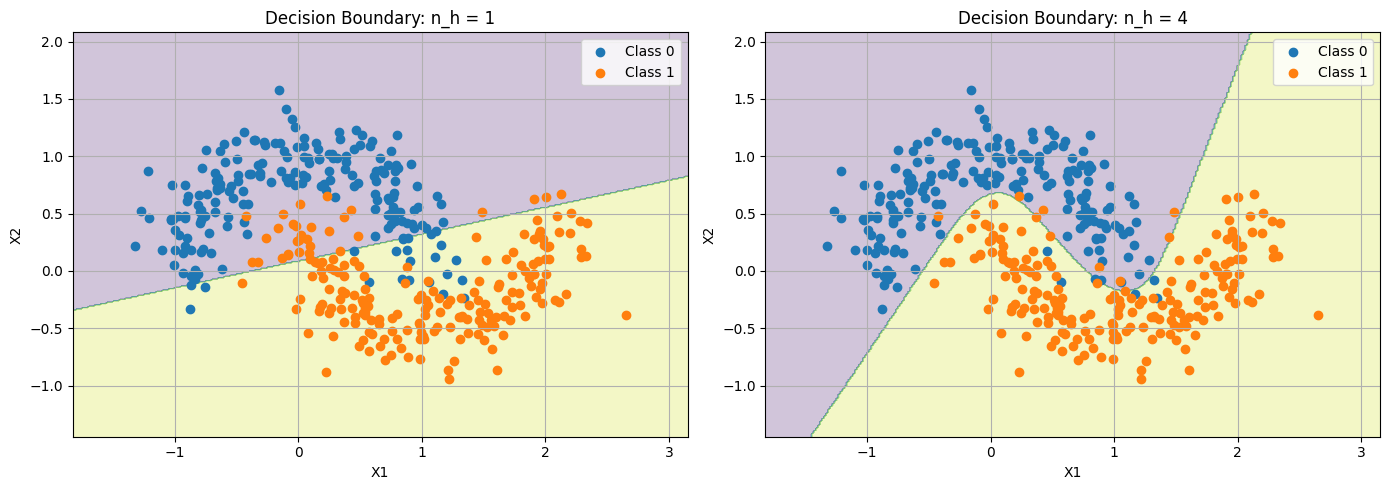

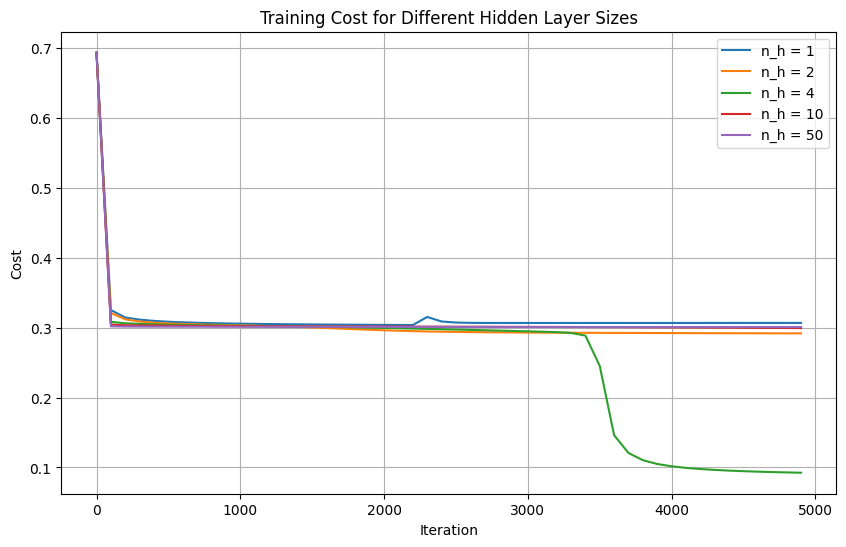



LARGE HIDDEN-LAYER ANALYSIS
Among n_h >= 10, the lowest test accuracy was observed at n_h = 10.
Training accuracy = 85.62%
Test accuracy     = 90.00%

Possible hypothesis:
A larger hidden layer can be harder to optimize with the same learning rate and initialization scale. With tanh activations, some neurons may enter saturated regions, making gradients very small. Therefore, a worse result does not necessarily mean overfitting.


In [4]:
# ============================================================
# TASK 6 — EFFECT OF HIDDEN LAYER SIZE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PART 1 — CREATE DATASET
# ============================================================

np.random.seed(1)

m = 400

# -----------------------------
# Class 0
# -----------------------------

m0 = m // 2

theta0 = np.linspace(0, np.pi, m0)

x0 = np.cos(theta0)
y0 = np.sin(theta0)

x0 = x0 + 0.20 * np.random.randn(m0)
y0 = y0 + 0.20 * np.random.randn(m0)


# -----------------------------
# Class 1
# -----------------------------

m1 = m - m0

theta1 = np.linspace(0, np.pi, m1)

x1 = 1 - np.cos(theta1)
y1 = 0.5 - np.sin(theta1)

x1 = x1 + 0.20 * np.random.randn(m1)
y1 = y1 + 0.20 * np.random.randn(m1)


# -----------------------------
# Combine
# -----------------------------

X = np.vstack([
    np.concatenate([x0, x1]),
    np.concatenate([y0, y1])
])

Y = np.concatenate([
    np.zeros(m0),
    np.ones(m1)
]).reshape(1, m)


# ============================================================
# SHUFFLE
# ============================================================

indices = np.random.permutation(m)

X = X[:, indices]
Y = Y[:, indices]


# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train = X[:, :320]
Y_train = Y[:, :320]

X_test = X[:, 320:]
Y_test = Y[:, 320:]


print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test :", X_test.shape)
print("Y_test :", Y_test.shape)


# ============================================================
# PART 2 — SIGMOID
# ============================================================

def sigmoid(z):

    z = np.asarray(z)

    result = np.empty_like(z, dtype=float)

    positive = z >= 0
    negative = ~positive

    result[positive] = 1 / (
        1 + np.exp(-z[positive])
    )

    exp_z = np.exp(z[negative])

    result[negative] = (
        exp_z / (1 + exp_z)
    )

    return result


# ============================================================
# PART 3 — COST FUNCTION
# ============================================================

def compute_cost(A2, Y):

    m = Y.shape[1]

    epsilon = 1e-15

    A2 = np.clip(
        A2,
        epsilon,
        1 - epsilon
    )

    cost = -(1 / m) * np.sum(
        Y * np.log(A2)
        +
        (1 - Y) * np.log(1 - A2)
    )

    return cost


# ============================================================
# PART 4 — INITIALIZE NETWORK
# ============================================================

def initialize_2layer(n_x, n_h, n_y):

    # Important:
    # Same initialization scale = 0.01
    W1 = np.random.randn(
        n_h,
        n_x
    ) * 0.01

    b1 = np.zeros(
        (n_h, 1)
    )

    W2 = np.random.randn(
        n_y,
        n_h
    ) * 0.01

    b2 = np.zeros(
        (n_y, 1)
    )

    parameters = {
        "W1": W1,
        "b1": b1,
        "W2": W2,
        "b2": b2
    }

    return parameters


# ============================================================
# PART 5 — FORWARD PROPAGATION
# ============================================================

def forward_2layer(X, parameters):

    W1 = parameters["W1"]
    b1 = parameters["b1"]

    W2 = parameters["W2"]
    b2 = parameters["b2"]

    # Hidden layer
    Z1 = W1 @ X + b1

    A1 = np.tanh(Z1)

    # Output layer
    Z2 = W2 @ A1 + b2

    A2 = sigmoid(Z2)

    cache = {
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2
    }

    return A2, cache


# ============================================================
# PART 6 — BACKWARD PROPAGATION
# ============================================================

def backward_2layer(
    X,
    Y,
    parameters,
    cache
):

    W2 = parameters["W2"]

    A1 = cache["A1"]
    A2 = cache["A2"]

    m = X.shape[1]

    # Output layer
    dZ2 = A2 - Y

    dW2 = (
        1 / m
    ) * (
        dZ2 @ A1.T
    )

    db2 = (
        1 / m
    ) * np.sum(
        dZ2,
        axis=1,
        keepdims=True
    )

    # Hidden layer
    dZ1 = (
        W2.T @ dZ2
    ) * (
        1 - np.power(A1, 2)
    )

    dW1 = (
        1 / m
    ) * (
        dZ1 @ X.T
    )

    db1 = (
        1 / m
    ) * np.sum(
        dZ1,
        axis=1,
        keepdims=True
    )

    grads = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2
    }

    return grads


# ============================================================
# PART 7 — UPDATE
# ============================================================

def update_2layer(
    parameters,
    grads,
    learning_rate
):

    parameters["W1"] = (
        parameters["W1"]
        - learning_rate * grads["dW1"]
    )

    parameters["b1"] = (
        parameters["b1"]
        - learning_rate * grads["db1"]
    )

    parameters["W2"] = (
        parameters["W2"]
        - learning_rate * grads["dW2"]
    )

    parameters["b2"] = (
        parameters["b2"]
        - learning_rate * grads["db2"]
    )

    return parameters


# ============================================================
# PART 8 — TRAIN NETWORK
# ============================================================

def train_2layer(
    X,
    Y,
    n_h,
    iterations=5000,
    learning_rate=0.5
):

    n_x = X.shape[0]
    n_y = Y.shape[0]

    parameters = initialize_2layer(
        n_x,
        n_h,
        n_y
    )

    costs = []

    for i in range(iterations):

        # Forward
        A2, cache = forward_2layer(
            X,
            parameters
        )

        # Cost
        cost = compute_cost(
            A2,
            Y
        )

        # Backward
        grads = backward_2layer(
            X,
            Y,
            parameters,
            cache
        )

        # Update
        parameters = update_2layer(
            parameters,
            grads,
            learning_rate
        )

        # Store cost
        if i % 100 == 0:
            costs.append(cost)

    # Calculate final cost after training
    final_A2, final_cache = forward_2layer(
        X,
        parameters
    )

    final_cost = compute_cost(
        final_A2,
        Y
    )

    return parameters, costs, final_cost


# ============================================================
# PART 9 — PREDICTION
# ============================================================

def predict_2layer(
    X,
    parameters
):

    A2, cache = forward_2layer(
        X,
        parameters
    )

    predictions = (
        A2 >= 0.5
    ).astype(int)

    return predictions


# ============================================================
# PART 10 — ACCURACY
# ============================================================

def accuracy(
    Y_true,
    Y_pred
):

    return np.mean(
        Y_true == Y_pred
    ) * 100


# ============================================================
# PART 11 — TRAIN FOR DIFFERENT HIDDEN SIZES
# ============================================================

hidden_sizes = [
    1,
    2,
    4,
    10,
    50
]

results = []

trained_models = {}


print("\n")
print("==============================================")
print("EFFECT OF HIDDEN LAYER SIZE")
print("==============================================")


for n_h in hidden_sizes:

    print("\n----------------------------------------------")
    print(f"Training with n_h = {n_h}")
    print("----------------------------------------------")

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    parameters, costs, final_cost = train_2layer(
        X_train,
        Y_train,
        n_h=n_h,
        iterations=5000,
        learning_rate=0.5
    )

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    train_pred = predict_2layer(
        X_train,
        parameters
    )

    test_pred = predict_2layer(
        X_test,
        parameters
    )

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    train_acc = accuracy(
        Y_train,
        train_pred
    )

    test_acc = accuracy(
        Y_test,
        test_pred
    )

    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------

    results.append([
        n_h,
        final_cost,
        train_acc,
        test_acc
    ])

    trained_models[n_h] = {
        "parameters": parameters,
        "costs": costs
    }

    print(
        f"Final Cost       = {final_cost:.6f}"
    )

    print(
        f"Training Accuracy = {train_acc:.2f}%"
    )

    print(
        f"Test Accuracy     = {test_acc:.2f}%"
    )


# ============================================================
# PART 12 — PRINT RESULTS TABLE
# ============================================================

print("\n")
print("==============================================================")
print("RESULTS TABLE")
print("==============================================================")

print(
    f"{'n_h':<8}"
    f"{'Final Cost':<18}"
    f"{'Train Accuracy':<20}"
    f"{'Test Accuracy':<20}"
)

print("-" * 66)

for row in results:

    n_h = row[0]
    final_cost = row[1]
    train_acc = row[2]
    test_acc = row[3]

    print(
        f"{n_h:<8}"
        f"{final_cost:<18.6f}"
        f"{train_acc:<20.2f}%"
        f"{test_acc:<20.2f}%"
    )


# ============================================================
# PART 13 — FIND BEST TEST ACCURACY
# ============================================================

best_result = max(
    results,
    key=lambda row: row[3]
)

best_n_h = best_result[0]
best_test_accuracy = best_result[3]

print("\n")
print("==============================================")
print("BEST TEST ACCURACY")
print("==============================================")

print(
    f"Best n_h based on test accuracy: {best_n_h}"
)

print(
    f"Test accuracy: {best_test_accuracy:.2f}%"
)


# ============================================================
# PART 14 — DECISION BOUNDARY FUNCTION
# ============================================================

def plot_boundary(
    X,
    Y,
    parameters,
    title,
    ax
):

    # Grid limits
    x_min = X[0, :].min() - 0.5
    x_max = X[0, :].max() + 0.5

    y_min = X[1, :].min() - 0.5
    y_max = X[1, :].max() + 0.5

    # Grid
    xx, yy = np.meshgrid(
        np.linspace(
            x_min,
            x_max,
            300
        ),
        np.linspace(
            y_min,
            y_max,
            300
        )
    )

    grid = np.c_[
        xx.ravel(),
        yy.ravel()
    ].T

    # Predictions
    predictions = predict_2layer(
        grid,
        parameters
    )

    predictions = predictions.reshape(
        xx.shape
    )

    # Decision regions
    ax.contourf(
        xx,
        yy,
        predictions,
        alpha=0.25
    )

    # Class 0
    ax.scatter(
        X[0, Y[0] == 0],
        X[1, Y[0] == 0],
        label="Class 0"
    )

    # Class 1
    ax.scatter(
        X[0, Y[0] == 1],
        X[1, Y[0] == 1],
        label="Class 1"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")

    ax.set_title(title)

    ax.legend()

    ax.grid(True)


# ============================================================
# PART 15 — DECISION BOUNDARY FOR n_h = 1
# AND BEST n_h
# ============================================================

model_n1 = trained_models[1]["parameters"]

model_best = trained_models[
    best_n_h
]["parameters"]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# n_h = 1
plot_boundary(
    X,
    Y,
    model_n1,
    "Decision Boundary: n_h = 1",
    axes[0]
)


# Best n_h
plot_boundary(
    X,
    Y,
    model_best,
    f"Decision Boundary: n_h = {best_n_h}",
    axes[1]
)


plt.tight_layout()

plt.show()


# ============================================================
# PART 16 — DISPLAY COST CURVES
# ============================================================

plt.figure(figsize=(10, 6))

for n_h in hidden_sizes:

    costs = trained_models[
        n_h
    ]["costs"]

    iterations_plot = np.arange(
        0,
        len(costs) * 100,
        100
    )

    plt.plot(
        iterations_plot,
        costs,
        label=f"n_h = {n_h}"
    )

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.title(
    "Training Cost for Different Hidden Layer Sizes"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# PART 17 — IDENTIFY NOTICEABLY WORSE LARGE MODEL
# ============================================================

print("\n")
print("==============================================")
print("LARGE HIDDEN-LAYER ANALYSIS")
print("==============================================")


large_results = [
    row for row in results
    if row[0] >= 10
]

# Find the largest-size model with the lowest test accuracy
worst_large = min(
    large_results,
    key=lambda row: row[3]
)

print(
    f"Among n_h >= 10, the lowest test accuracy "
    f"was observed at n_h = {worst_large[0]}."
)

print(
    f"Training accuracy = {worst_large[2]:.2f}%"
)

print(
    f"Test accuracy     = {worst_large[3]:.2f}%"
)

print("\nPossible hypothesis:")
print(
    "A larger hidden layer can be harder to optimize with the "
    "same learning rate and initialization scale. With tanh "
    "activations, some neurons may enter saturated regions, "
    "making gradients very small. Therefore, a worse result "
    "does not necessarily mean overfitting."
)